In [ ]:
"""Column	Purpose
-------------------------
study_hours--->Daily study hours
attendance---->Attendance percentage
sleep_hours--->Sleep hours
previous_score-->Previous exam score
practice_test-->Practice tests completed
internet_access-->Yes/no category
exam_score-->Target value to predict"""

In [6]:
import matplotlib.pyplot as plt
import pandas as pd


In [1]:

df = pd.read_csv("/content/student_scores.csv")

print(df.shape)
display(df.head())

(3000, 7)


,study_hours,attendance,sleep_hours,previous_score,practice_tests,internet_access,exam_score
0,3.75,80.36,7.89,93.09,19,yes,77.58
1,9.51,87.80,5.03,62.03,6,yes,85.59
2,7.32,55.03,9.23,77.99,2,yes,71.44
3,5.99,77.49,7.68,54.88,4,no,73.39
4,1.56,74.30,4.94,70.40,0,yes,42.09


In [2]:
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   study_hours      3000 non-null   float64
 1   attendance       3000 non-null   float64
 2   sleep_hours      3000 non-null   float64
 3   previous_score   3000 non-null   float64
 4   practice_tests   3000 non-null   int64  
 5   internet_access  3000 non-null   object 
 6   exam_score       3000 non-null   float64
dtypes: float64(5), int64(1), object(1)
memory usage: 164.2+ KB

Missing values:
study_hours        0
attendance         0
sleep_hours        0
previous_score     0
practice_tests     0
internet_access    0
exam_score         0
dtype: int64

Duplicate rows: 0


In [3]:
display(df.describe())

,study_hours,attendance,sleep_hours,previous_score,practice_tests,exam_score
count,3000.000000,3000.000000,3000.00000,3000.000000,3000.000000,3000.000000
mean,4.998947,69.658903,6.92429,60.206297,10.087333,64.615887
std,2.916585,17.245379,1.71347,23.060120,6.096783,14.963130
min,0.000000,40.000000,4.00000,20.000000,0.000000,22.750000
25%,2.457500,54.745000,5.45000,40.362500,5.000000,53.447500
50%,5.050000,69.280000,6.89000,59.925000,10.000000,64.560000
75%,7.542500,84.312500,8.37000,80.415000,15.000000,75.727500
max,10.000000,99.970000,10.00000,99.970000,20.000000,100.000000


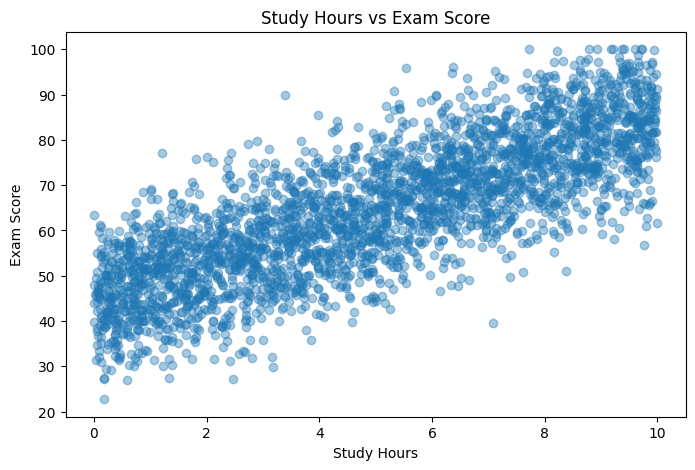

In [7]:
plt.figure(figsize=(8, 5))
plt.scatter(df["study_hours"], df["exam_score"], alpha=0.4)
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Study Hours vs Exam Score")
plt.show()

In [8]:
print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values:
study_hours        0
attendance         0
sleep_hours        0
previous_score     0
practice_tests     0
internet_access    0
exam_score         0
dtype: int64
Duplicate rows: 0


Understand this:
- X contains the information used to predict the score.
- y contains the exam score we want the model to predict.
- axis=1 means we're dropping a column.


In [9]:
X = df.drop("exam_score", axis=1)
y = df["exam_score"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3000, 6)
y shape: (3000,)


3. Encode the categorical column
Our internet_access column contains text values (yes and no). The model needs numerical inputs, so we'll use one-hot encoding.

In [10]:
X = pd.get_dummies(
    X,
    columns=["internet_access"],
    dtype=int
)

display(X.head())
print(X.shape)

,study_hours,attendance,sleep_hours,previous_score,practice_tests,internet_access_no,internet_access_yes
0,3.75,80.36,7.89,93.09,19,0,1
1,9.51,87.80,5.03,62.03,6,0,1
2,7.32,55.03,9.23,77.99,2,0,1
3,5.99,77.49,7.68,54.88,4,1,0
4,1.56,74.30,4.94,70.40,0,0,1


(3000, 7)


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (2400, 7)
Testing features: (600, 7)
